# Obesity Prediction: Logistic Regression and Random Forest




## 1. Import libraries

We will use pandas and NumPy for data handling, scikit-learn for splitting, preprocessing, models and evaluation, and Matplotlib for ROC curves.

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

## 2. Load the cleaned dataset

This relative path assumes the notebook is saved in the repository's `Python/` folder and the CSV is in `data/`. If your folder layout differs, update the path below.

In [42]:
df = pd.read_csv("../data/obesity_cleaned.csv")

In [43]:
df.head()

,gender,age,height,weight,family_history,high_calorie,smoke,physical_activity,alcohol,obesity
0,0,21,1.62,64.0,1,0,0,0,0,0
1,0,21,1.52,56.0,1,0,1,3,1,0
2,1,23,1.80,77.0,1,0,0,2,2,0
3,1,27,1.80,87.0,0,0,0,2,2,0
4,1,22,1.78,89.8,0,0,0,0,1,0


In [44]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (2103, 10)

Columns:
['gender', 'age', 'height', 'weight', 'family_history', 'high_calorie', 'smoke', 'physical_activity', 'alcohol', 'obesity']


In [45]:
print("\nMissing values by column:")
print(df.isna().sum())


Missing values by column:
gender               0
age                  0
height               0
weight               0
family_history       0
high_calorie         0
smoke                0
physical_activity    0
alcohol              0
obesity              0
dtype: int64


## 3. Define predictors and target

The target column is expected to be named `obesity`, coded as 0 and 1. We exclude it from the predictors to prevent target leakage.

In [46]:
target = "obesity"

if target not in df.columns:
    raise ValueError(
        f"Expected target column '{target}' was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

X = df.drop(columns=[target, "height"]).copy()

y = df[target].copy()

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts(dropna=False))

Predictor shape: (2103, 8)
Target shape: (2103,)

Target distribution:
obesity
0    1138
1     965
Name: count, dtype: int64


## 4. Train-test split

We use an 80:20 split.

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])
print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True))
print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True))

Training observations: 1682
Testing observations: 421

Training target proportions:
obesity
0    0.547562
1    0.452438
Name: proportion, dtype: float64

Testing target proportions:
obesity
0    0.515439
1    0.484561
Name: proportion, dtype: float64


## 5. Identify numerical and categorical predictors

Variables such as age, height and weight are numerical. Variables coded as categories (for example gender, family history, diet, smoking, physical activity and alcohol) should be treated as categorical even if their CSV values are numeric.

The code below uses known column names when present. Remaining object/category/bool columns are also treated as categorical.

In [48]:
known_categorical = [
    "gender",
    "family_history",
    "high_calorie",
    "smoke",
    "physical_activity",
    "alcohol"
]

categorical_columns = [
    col for col in known_categorical if col in X_train.columns
]

for col in X_train.columns:
    if (
        X_train[col].dtype == "object"
        or str(X_train[col].dtype) == "category"
        or X_train[col].dtype == "bool"
    ) and col not in categorical_columns:
        categorical_columns.append(col)

numeric_columns = [
    col for col in X_train.columns
    if col not in categorical_columns
]

print("Categorical columns:", categorical_columns)
print("Numerical columns:", numeric_columns)

Categorical columns: ['gender', 'family_history', 'high_calorie', 'smoke', 'physical_activity', 'alcohol']
Numerical columns: ['age', 'weight']


## 6. Encode categorical variables

We create dummy variables separately for training and test predictors.

In [ ]:
X_train_encoded = pd.get_dummies(
    X_train,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

# Ensure training and test datasets have identical feature columns

X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print("Training shape:", X_train_encoded.shape)
print("Test shape:", X_test_encoded.shape)

print(
    "Same feature columns:",
    X_train_encoded.columns.equals(X_test_encoded.columns)
)

Training data shape: (1682, 11)
Test data shape: (421, 11)


## 7. Scale numerical features for Logistic Regression

Scaling helps Logistic Regression when numerical predictors have different units. The scaler is fitted on the training data only. Random Forest will use the unscaled encoded data.

In [ ]:
# Create separate datasets for Logistic Regression

X_train_lr = X_train_encoded.copy()
X_test_lr = X_test_encoded.copy()

# Scale numerical predictors

scaler = StandardScaler()

X_train_lr[numeric_columns] = scaler.fit_transform(
    X_train_lr[numeric_columns]
)

X_test_lr[numeric_columns] = scaler.transform(
    X_test_lr[numeric_columns]
)

print("Training shape:", X_train_lr.shape)
print("Test shape:", X_test_lr.shape)

Training shape: (1682, 11)
Test shape: (421, 11)


## 8. Fit Logistic Regression

Fit the model on the training set and predict the held-out test observations.

In [ ]:
logistic_model = LogisticRegression(max_iter=2000, random_state=42)

logistic_model.fit(X_train_lr, y_train)

y_pred_lr = logistic_model.predict(X_test_lr)

y_prob_lr = logistic_model.predict_proba(X_test_lr)[:, 1]

## 9. Evaluate Logistic Regression

In [52]:
print("Logistic Regression")
print("-------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_lr, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_lr, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_lr), 4))

print("\nClassification report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression
-------------------
Accuracy: 0.9454
Precision: 0.9548
Recall: 0.9314
F1-score: 0.9429
ROC-AUC: 0.9912

Classification report:
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       217
           1       0.95      0.93      0.94       204

    accuracy                           0.95       421
   macro avg       0.95      0.94      0.95       421
weighted avg       0.95      0.95      0.95       421

Confusion matrix:
[[208   9]
 [ 14 190]]


## 10. Fit Random Forest

Random Forest can model nonlinear relationships and interactions. It does not need feature scaling, so it uses the one-hot encoded data before scaling.

In [53]:
random_forest_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

random_forest_model.fit(X_train_encoded, y_train)

y_pred_rf = random_forest_model.predict(X_test_encoded)
y_prob_rf = random_forest_model.predict_proba(X_test_encoded)[:, 1]

## 11. Evaluate Random Forest

In [54]:
print("Random Forest")
print("-------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_rf, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))

print("\nClassification report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest
-------------
Accuracy: 0.9762
Precision: 0.985
Recall: 0.9657
F1-score: 0.9752
ROC-AUC: 0.9967

Classification report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       217
           1       0.98      0.97      0.98       204

    accuracy                           0.98       421
   macro avg       0.98      0.98      0.98       421
weighted avg       0.98      0.98      0.98       421

Confusion matrix:
[[214   3]
 [  7 197]]


## 12. Compare the two models

Both models are evaluated on the same held-out test observations.

In [57]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf)
    ]
}).set_index("Model")

print(results.round(4))

                     Accuracy  Precision  Recall  F1-score  ROC-AUC
Model                                                              
Logistic Regression    0.9454     0.9548  0.9314    0.9429   0.9912
Random Forest          0.9762     0.9850  0.9657    0.9752   0.9967


## 13. Compare ROC curves

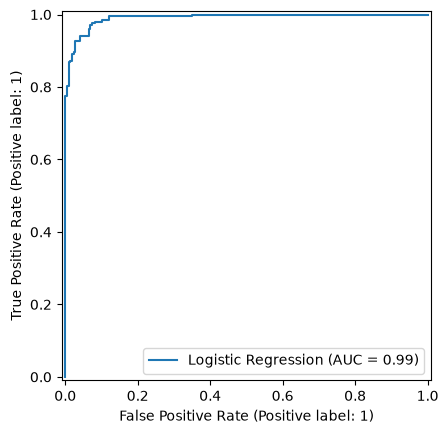

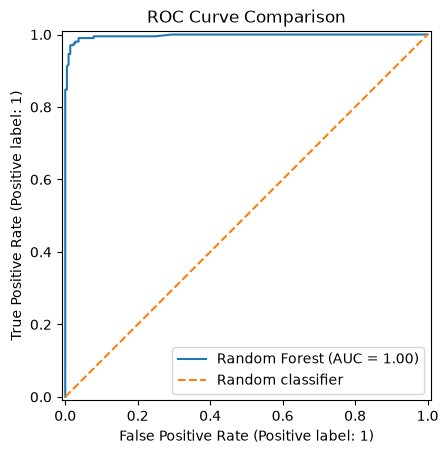

In [58]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_lr,
    name="Logistic Regression"
)

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_rf,
    name="Random Forest"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()